**Sephora Skincare Ingredients**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка данных
df = pd.read_csv("cosmetic_p.csv")

# Просмотр первых строк
print(df.head())

         Label           brand                                           name  \
0  Moisturizer          LA MER                                Crème de la Mer   
1  Moisturizer           SK-II                       Facial Treatment Essence   
2  Moisturizer  DRUNK ELEPHANT                     Protini™ Polypeptide Cream   
3  Moisturizer          LA MER                    The Moisturizing Soft Cream   
4  Moisturizer    IT COSMETICS  Your Skin But Better™ CC+™ Cream with SPF 50+   

   price  rank                                        ingredients  \
0    175   4.1  Algae (Seaweed) Extract, Mineral Oil, Petrolat...   
1    179   4.1  Galactomyces Ferment Filtrate (Pitera), Butyle...   
2     68   4.4  Water, Dicaprylyl Carbonate, Glycerin, Ceteary...   
3    175   3.8  Algae (Seaweed) Extract, Cyclopentasiloxane, P...   
4     38   4.1  Water, Snail Secretion Filtrate, Phenyl Trimet...   

   Combination  Dry  Normal  Oily  Sensitive  
0            1    1       1     1          1  
1   

In [ ]:
# Основная информация о данных
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1472 entries, 0 to 1471
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Label        1472 non-null   object 
 1   brand        1472 non-null   object 
 2   name         1472 non-null   object 
 3   price        1472 non-null   int64  
 4   rank         1472 non-null   float64
 5   ingredients  1472 non-null   object 
 6   Combination  1472 non-null   int64  
 7   Dry          1472 non-null   int64  
 8   Normal       1472 non-null   int64  
 9   Oily         1472 non-null   int64  
 10  Sensitive    1472 non-null   int64  
dtypes: float64(1), int64(6), object(4)
memory usage: 126.6+ KB
None


In [ ]:
# Статистическое описание числовых данных
print(df.describe())

             price         rank  Combination          Dry       Normal  \
count  1472.000000  1472.000000   1472.00000  1472.000000  1472.000000   
mean     55.584239     4.153261      0.65625     0.614130     0.652174   
std      45.014429     0.633918      0.47512     0.486965     0.476442   
min       3.000000     0.000000      0.00000     0.000000     0.000000   
25%      30.000000     4.000000      0.00000     0.000000     0.000000   
50%      42.500000     4.300000      1.00000     1.000000     1.000000   
75%      68.000000     4.500000      1.00000     1.000000     1.000000   
max     370.000000     5.000000      1.00000     1.000000     1.000000   

              Oily    Sensitive  
count  1472.000000  1472.000000  
mean      0.607337     0.513587  
std       0.488509     0.499985  
min       0.000000     0.000000  
25%       0.000000     0.000000  
50%       1.000000     1.000000  
75%       1.000000     1.000000  
max       1.000000     1.000000  


In [ ]:
print(df.isna().sum())  # Проверка пропусков

Label          0
brand          0
name           0
price          0
rank           0
ingredients    0
Combination    0
Dry            0
Normal         0
Oily           0
Sensitive      0
dtype: int64


In [ ]:
duplicated_rows = df.duplicated().sum()
print(f"There are {duplicated_rows} fully duplicated rows in the dataset.")

There are 0 fully duplicated rows in the dataset.


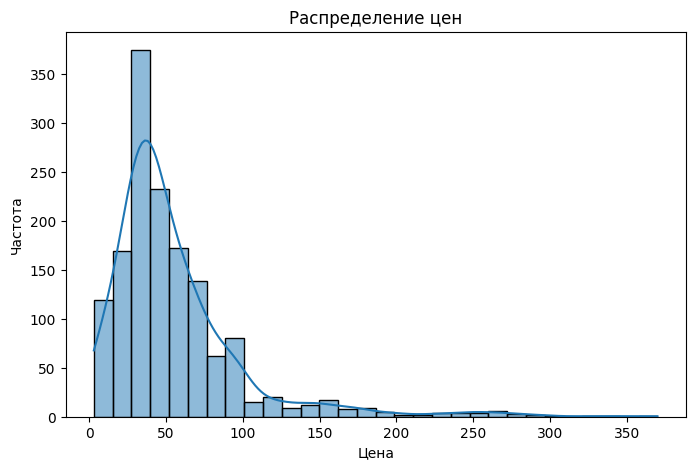

In [ ]:
#распределение цен
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Распределение цен")
plt.xlabel("Цена")
plt.ylabel("Частота")
plt.show()


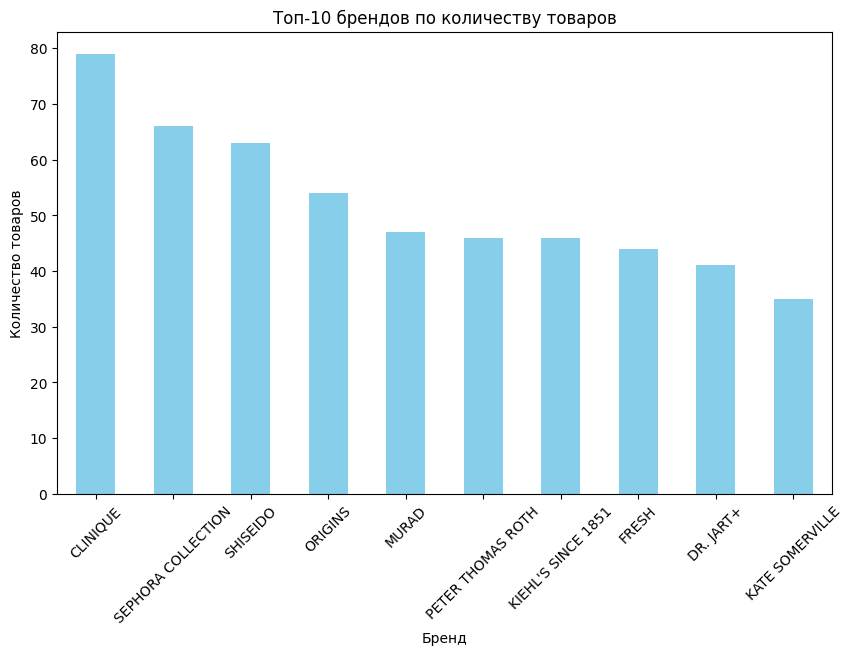

In [ ]:
plt.figure(figsize=(10, 6))
df["brand"].value_counts().head(10).plot(kind="bar", color="skyblue")
plt.title("Топ-10 брендов по количеству товаров")
plt.xlabel("Бренд")
plt.ylabel("Количество товаров")
plt.xticks(rotation=45)
plt.show()


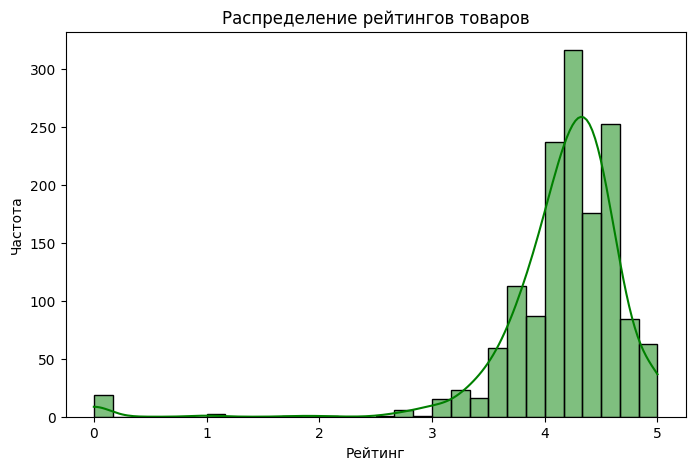

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df["rank"].dropna(), bins=30, kde=True, color="green")
plt.title("Распределение рейтингов товаров")
plt.xlabel("Рейтинг")
plt.ylabel("Частота")
plt.show()


<ipython-input-10-37d62498b0e4>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y="Ингредиент", x="Частота", data=top_ingredients, palette="coolwarm")


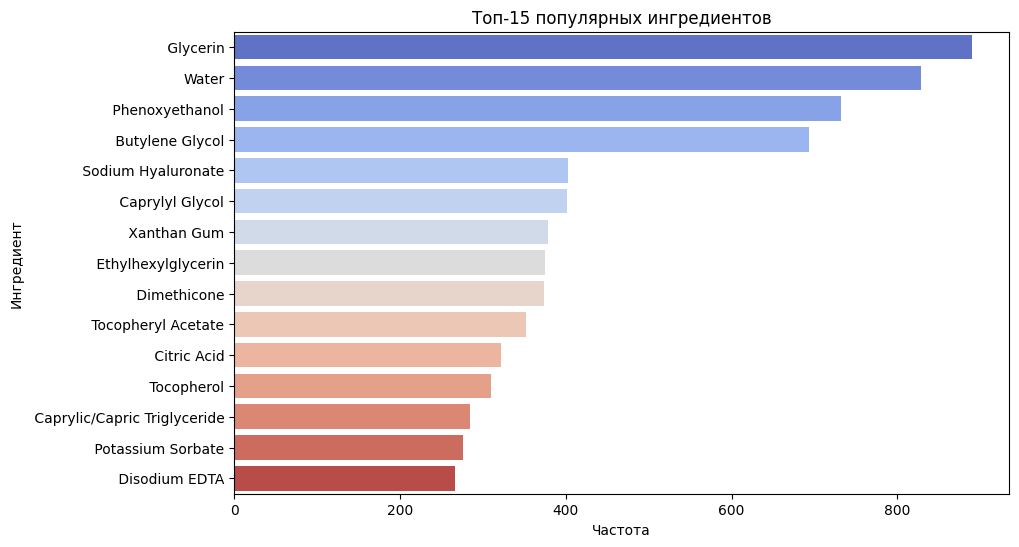

In [ ]:
from collections import Counter
import itertools

# Разбираем ингредиенты (предполагаем, что они разделены запятой)
all_ingredients = list(itertools.chain(*df["ingredients"].dropna().str.split(",")))
ingredient_counts = Counter(all_ingredients)

# Топ-15 ингредиентов
top_ingredients = pd.DataFrame(ingredient_counts.most_common(15), columns=["Ингредиент", "Частота"])

plt.figure(figsize=(10, 6))
sns.barplot(y="Ингредиент", x="Частота", data=top_ingredients, palette="coolwarm")
plt.title("Топ-15 популярных ингредиентов")
plt.show()


<ipython-input-11-2383a1cf2a83>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=skin_counts.index, y=skin_counts.values, palette="viridis")


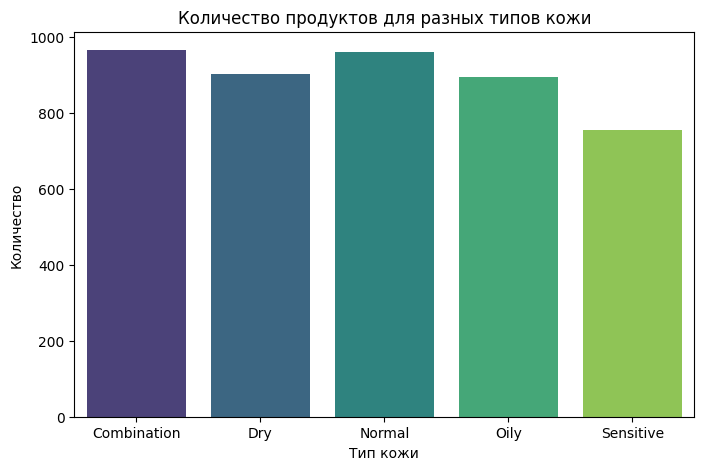

In [ ]:
skin_types = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]
skin_counts = df[skin_types].sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=skin_counts.index, y=skin_counts.values, palette="viridis")
plt.title("Количество продуктов для разных типов кожи")
plt.xlabel("Тип кожи")
plt.ylabel("Количество")
plt.show()


📌 зависимость цены и рейтинга

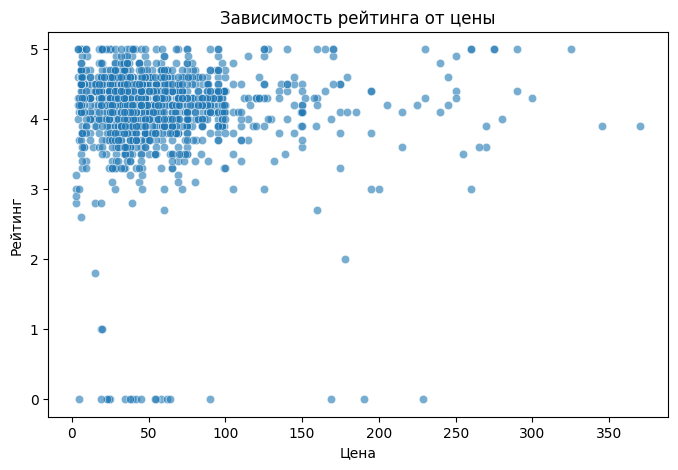

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["price"], y=df["rank"], alpha=0.6)
plt.title("Зависимость рейтинга от цены")
plt.xlabel("Цена")
plt.ylabel("Рейтинг")
plt.show()


📌 какие бренды делают продукты для определенного типа кожи

<ipython-input-13-2154b7be0e02>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=skin_brand_counts.index, x=skin_brand_counts.values, palette="magma")


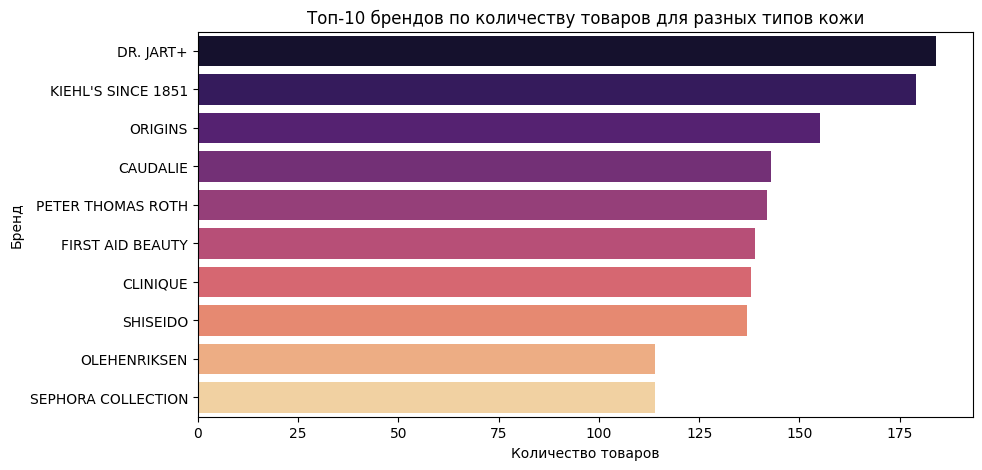

In [ ]:

skin_brand_counts = df.groupby("brand")[skin_types].sum().sum(axis=1).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(y=skin_brand_counts.index, x=skin_brand_counts.values, palette="magma")
plt.title("Топ-10 брендов по количеству товаров для разных типов кожи")
plt.xlabel("Количество товаров")
plt.ylabel("Бренд")
plt.show()


📌 Влияет ли цена на количество поддерживаемых типов кожи

<ipython-input-14-c6e7007af1ac>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="skin_type_count", y="price", data=df, palette="coolwarm")


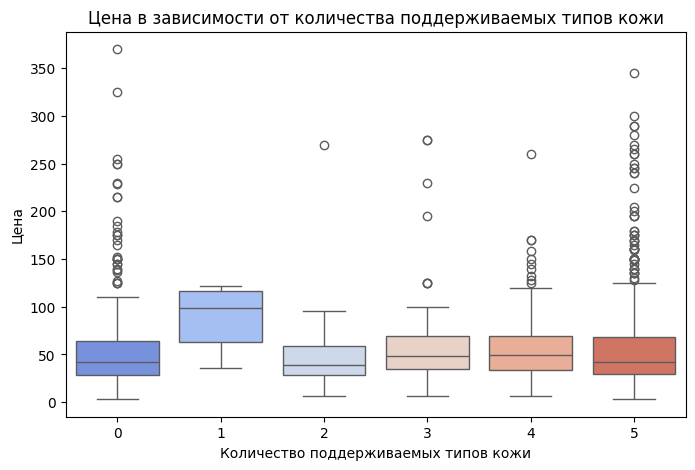

In [ ]:
df["skin_type_count"] = df[skin_types].sum(axis=1)

plt.figure(figsize=(8, 5))
sns.boxplot(x="skin_type_count", y="price", data=df, palette="coolwarm")
plt.title("Цена в зависимости от количества поддерживаемых типов кожи")
plt.xlabel("Количество поддерживаемых типов кожи")
plt.ylabel("Цена")
plt.show()


 Поиск паттернов
📌
Дешёвые vs дорогие бренды и их рейтинги

<ipython-input-15-ace5b572f560>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="price_category", y="rank", data=df, palette="Set2")


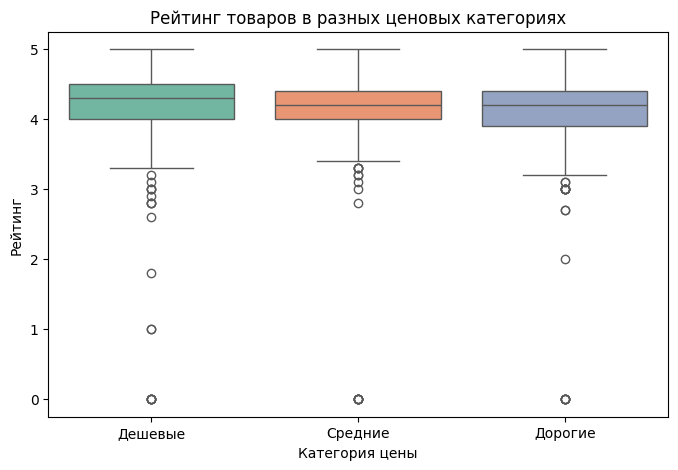

In [ ]:
df["price_category"] = pd.qcut(df["price"], q=3, labels=["Дешевые", "Средние", "Дорогие"])

plt.figure(figsize=(8, 5))
sns.boxplot(x="price_category", y="rank", data=df, palette="Set2")
plt.title("Рейтинг товаров в разных ценовых категориях")
plt.xlabel("Категория цены")
plt.ylabel("Рейтинг")
plt.show()


 Какие ингредиенты встречаются в продуктах для разных типов кожи

In [ ]:
for skin_type in skin_types:
    filtered_df = df[df[skin_type] == 1]
    all_ingr = list(itertools.chain(*filtered_df["ingredients"].dropna().str.split(",")))
    ingr_counts = Counter(all_ingr).most_common(10)

    print(f"\n🔹 Топ-10 ингредиентов для {skin_type} кожи:")
    for ing, count in ingr_counts:
        print(f"{ing}: {count} раз")



🔹 Топ-10 ингредиентов для Combination кожи:
 Glycerin: 638 раз
Water: 587 раз
 Phenoxyethanol: 503 раз
 Butylene Glycol: 477 раз
 Ethylhexylglycerin: 291 раз
 Caprylyl Glycol: 290 раз
 Xanthan Gum: 280 раз
 Sodium Hyaluronate: 273 раз
 Dimethicone: 246 раз
 Citric Acid: 234 раз

🔹 Топ-10 ингредиентов для Dry кожи:
 Glycerin: 601 раз
Water: 545 раз
 Phenoxyethanol: 472 раз
 Butylene Glycol: 445 раз
 Ethylhexylglycerin: 272 раз
 Caprylyl Glycol: 271 раз
 Xanthan Gum: 265 раз
 Sodium Hyaluronate: 254 раз
 Dimethicone: 237 раз
 Citric Acid: 226 раз

🔹 Топ-10 ингредиентов для Normal кожи:
 Glycerin: 637 раз
Water: 584 раз
 Phenoxyethanol: 496 раз
 Butylene Glycol: 472 раз
 Caprylyl Glycol: 290 раз
 Ethylhexylglycerin: 287 раз
 Xanthan Gum: 280 раз
 Sodium Hyaluronate: 271 раз
 Dimethicone: 253 раз
 Citric Acid: 236 раз

🔹 Топ-10 ингредиентов для Oily кожи:
 Glycerin: 591 раз
Water: 545 раз
 Phenoxyethanol: 472 раз
 Butylene Glycol: 447 раз
 Caprylyl Glycol: 274 раз
 Ethylhexylglycerin: 266

<Figure size 1200x600 with 0 Axes>

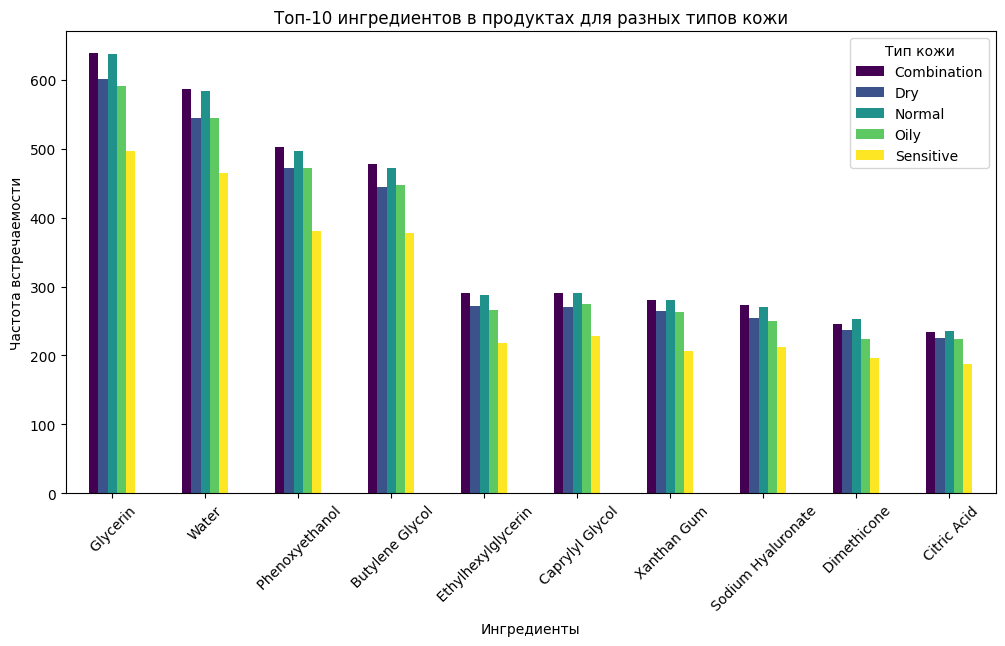

In [ ]:
skin_types = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]

# Создаем общий список ингредиентов для каждого типа кожи
skin_ingr_counts = {}

for skin_type in skin_types:
    filtered_df = df[df[skin_type] == 1]  # Оставляем только продукты для данного типа кожи
    all_ingr = list(itertools.chain(*filtered_df["ingredients"].dropna().str.split(",")))
    ingr_counts = Counter(all_ingr).most_common(10)  # Топ-10 ингредиентов
    skin_ingr_counts[skin_type] = dict(ingr_counts)

# Преобразуем в DataFrame для построения графика
ingredients_df = pd.DataFrame(skin_ingr_counts).fillna(0)

# Построение графика
plt.figure(figsize=(12, 6))
ingredients_df.plot(kind="bar", colormap="viridis", figsize=(12, 6))
plt.title("Топ-10 ингредиентов в продуктах для разных типов кожи")
plt.xlabel("Ингредиенты")
plt.ylabel("Частота встречаемости")
plt.xticks(rotation=45)
plt.legend(title="Тип кожи")
plt.show()

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128150 (\N{SPARKLING HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


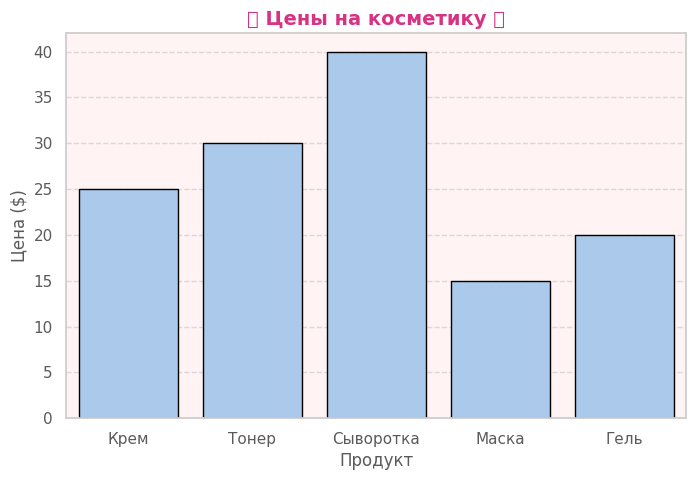

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Установим стиль
sns.set_theme(style="whitegrid", palette="pastel")

# Создадим диаграмму
plt.figure(figsize=(8, 5))
sns.barplot(x="Название", y="Цена ($)", data=df, edgecolor="black")

# Улучшенный дизайн
plt.title("💖 Цены на косметику 💖", fontsize=14, fontweight="bold", color="#D63384")
plt.xlabel("Продукт", fontsize=12, color="#5A5A5A")
plt.ylabel("Цена ($)", fontsize=12, color="#5A5A5A")
plt.xticks(fontsize=11, color="#5A5A5A")
plt.yticks(fontsize=11, color="#5A5A5A")

# Добавляем фон
plt.gca().set_facecolor("#FFF3F3")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()



1. Классификация: Предсказание, подходит ли продукт для жирной кожи (Oily)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Загрузка данных
df = pd.read_csv("cosmetic_p.csv")

# Удалим строки с пропущенными значениями в важных колонках
df_cls = df.dropna(subset=['price', 'rank', 'brand', 'Oily'])

# Кодируем категориальные признаки
df_cls['brand_encoded'] = df_cls['brand'].astype('category').cat.codes

# Целевая переменная: подходит ли для жирной кожи
df_cls['target'] = df_cls['Oily'].astype(int)

# Признаки
features = ['price', 'rank', 'brand_encoded']
X = df_cls[features]
y = df_cls['target']

# Обучение модели
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_cls = RandomForestClassifier(random_state=42)
model_cls.fit(X_train, y_train)

# Оценка
y_pred = model_cls.predict(X_test)
print("🔹 Классификация по жирной коже:\n", classification_report(y_test, y_pred))


🔹 Классификация по жирной коже:
               precision    recall  f1-score   support

           0       0.49      0.40      0.44       121
           1       0.63      0.71      0.67       174

    accuracy                           0.58       295
   macro avg       0.56      0.56      0.56       295
weighted avg       0.57      0.58      0.58       295



2. Регрессия: Предсказание цены (price) по другим признакам

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Удалим строки с пропущенными значениями
df_reg = df.dropna(subset=['price', 'rank', 'brand'])

# Кодируем бренд
df_reg['brand_encoded'] = df_reg['brand'].astype('category').cat.codes

# Целевая переменная — price
X = df_reg[['rank', 'brand_encoded']]
y = df_reg['price']

# Обучение модели
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_reg = RandomForestRegressor(random_state=42)
model_reg.fit(X_train, y_train)

# Оценка
y_pred = model_reg.predict(X_test)
print("🔹 Регрессия по цене:")
print("MSE:", mean_squared_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))


🔹 Регрессия по цене:
MSE: 1326.0069998681206
R²: 0.3541274882354074


3. NLP + Классификация: Используем ингредиенты для предсказания типа кожи

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Только строки, где есть текст и инфа по коже
df_nlp = df.dropna(subset=['ingredients', 'Oily'])

# Цель — подходит ли для жирной кожи
y = df_nlp['Oily'].astype(int)

# TF-IDF преобразование текста
tfidf = TfidfVectorizer(max_features=1000, stop_words='english')
X = tfidf.fit_transform(df_nlp['ingredients'])

# Обучение
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model_nlp = LogisticRegression(max_iter=1000)
model_nlp.fit(X_train, y_train)

# Оценка
y_pred = model_nlp.predict(X_test)
print("🔹 NLP по ингредиентам (предсказание жирной кожи):\n", classification_report(y_test, y_pred))


🔹 NLP по ингредиентам (предсказание жирной кожи):
               precision    recall  f1-score   support

           0       0.67      0.36      0.46       121
           1       0.66      0.88      0.76       174

    accuracy                           0.66       295
   macro avg       0.67      0.62      0.61       295
weighted avg       0.67      0.66      0.64       295



**Цель: Предсказание ранга (`rank`):::**

Мы решаем задачу регрессии, так как переменная `rank` является числовой.

**Почему `rank`?**
Рейтинг продукта — важный показатель его успешности, востребованности и доверия со стороны пользователей. Возможность предсказать рейтинг на основе параметров (таких как цена, бренд и др.) может быть полезна для продуктовых команд, маркетинга и рекомендательных систем.

**Возможные нюансы:**
- **Мультиколлинеарность** — в нашем случае признаки простые (например, цена и бренд), поэтому вероятность сильной коллинеарности невелика, но можно дополнительно проверить с помощью корреляционной матрицы.
- **Шкалирование** — для линейной регрессии и других моделей это важно, особенно если признаки разномасштабные (например, цена и код бренда).
- **Дисбаланс** не является проблемой в регрессии, в отличие от классификации.



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
from sklearn.preprocessing import LabelEncoder

# Кодируем текстовую колонку 'brand' в числовую
le = LabelEncoder()
df['brand_encoded'] = le.fit_transform(df['brand'])

# Разделение признаков и целевой переменной
X = df[['price', 'brand_encoded']]
y = df['rank']

# Делим данные
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Обучение модели
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Предсказания
y_pred = model.predict(X_test_scaled)

# Метрики
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")


MAE: 0.35
RMSE: 0.55
R²: -0.01


## Классификация категорий `rank`

Мы преобразовали задачу из регрессии в **многоклассовую классификацию**, разделив переменную `rank` на три категории:
- `low` (rank < 3)
- `medium` (3 ≤ rank < 4)
- `high` (rank ≥ 4)

В качестве признаков были использованы:
- `price`
- `brand_encoded` (категориально закодированный бренд)
- `ingredients_count` (количество ингредиентов)
- типы кожи: `Combination`, `Dry`, `Normal`, `Oily`, `Sensitive`

Для обучения использовался алгоритм **Random Forest Classifier**, хорошо подходящий для работы с разнородными признаками и устойчивый к переобучению.

### Результаты модели:
- **Accuracy (точность)**: 76%
- **F1-score для категории `high`** — 0.86, модель хорошо распознаёт популярные продукты
- **F1-score для `medium` и `low`** — значительно ниже, особенно `low`, которая  не распознаётся (0.00)

Из 295 примеров:
- `high`: 229 (77%)
- `medium`: 59 (20%)
- `low`: 7 (2%)

---



In [ ]:
def categorize_rank(rank):
    if rank < 3:
        return 'low'
    elif rank < 4:
        return 'medium'
    else:
        return 'high'

df['rank_category'] = df['rank'].apply(categorize_rank)
# Добавим числовой признак ingredients_count
df['ingredients_count'] = df['ingredients'].fillna('').apply(lambda x: len(x.split(',')))

# Категориальные признаки: brand
df['brand_encoded'] = df['brand'].astype('category').cat.codes

# Подготовка признаков
features = ['price', 'brand_encoded', 'ingredients_count', 'Combination', 'Dry', 'Normal', 'Oily', 'Sensitive']
X = df[features]
y = df['rank_category']
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Обучим модель
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# Предсказания
y_pred = clf.predict(X_test)

# Оценим качество
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))


[[215   1  13]
 [  6   0   1]
 [ 50   1   8]]
              precision    recall  f1-score   support

        high       0.79      0.94      0.86       229
         low       0.00      0.00      0.00         7
      medium       0.36      0.14      0.20        59

    accuracy                           0.76       295
   macro avg       0.39      0.36      0.35       295
weighted avg       0.69      0.76      0.71       295



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report


gb_model = GradientBoostingClassifier()


gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)


print("Gradient Boosting Classification Report:")
print(classification_report(y_test, y_pred_gb))


Gradient Boosting Classification Report:
              precision    recall  f1-score   support

        high       0.77      0.95      0.85       229
         low       0.00      0.00      0.00         7
      medium       0.11      0.02      0.03        59

    accuracy                           0.74       295
   macro avg       0.29      0.32      0.29       295
weighted avg       0.62      0.74      0.67       295



In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2', None]
}


grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,               # 5-кратная кросс-валидация
    n_jobs=-1,          # Использовать все ядра процессора
    verbose=2,          # Подробный вывод
    scoring='accuracy'  # Метрика для оптимизации
)

grid_search.fit(X_train, y_train)



Fitting 5 folds for each of 108 candidates, totalling 540 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'max_features': ['sqrt', 'log2', None],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy', verbose=2)

**price** — цена косметического продукта

**rank **— рейтинг (популярность/оценка)

**brand_encoded** — категориальный признак, кодировка бренда

Лучшая модель

RandomForestClassifier(
    max_depth=10,
    max_features=None,
    min_samples_leaf=2,
    n_estimators=50,
    random_state=42
)


***Какие признаки, по моему мнению, наиболее важны?:***


brand_encoded — разные бренды могут использовать разные формулы и подходы к косметике, что влияет на подходящесть для жирной кожи. Этот признак может быть очень значимым.

rank — если рейтинг отражает мнение пользователей или экспертов, он может хорошо коррелировать с качеством и подходящестью продукта, значит, тоже важен.

price — цена — косвенный показатель, связанный с сегментом продукта, но не всегда напрямую с эффектом, поэтому, вероятно, важность ниже.






In [ ]:
features = ['price', 'rank', 'brand_encoded']

importances = grid_search.best_estimator_.feature_importances_
for feature, importance in zip(features, importances):
    print(f"{feature}: {importance:.4f}")



price: 0.5031
rank: 0.4969


price (цена) и rank (рейтинг) — ключевые факторы, по которым модель классифицирует, подходит ли продукт для жирной кожи.

Оценка важности признаков с помощью встроенного метода RandomForest

Важность признаков:
price: 0.5031
rank: 0.4969


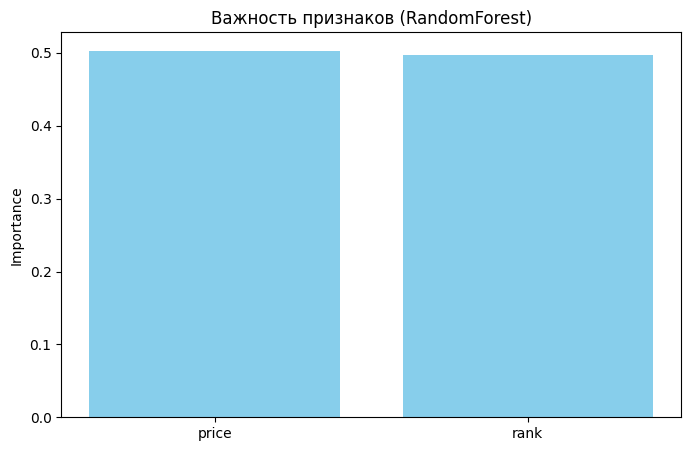

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Берём лучшую модель после GridSearchCV
best_model = grid_search.best_estimator_

# Получаем важности признаков
importances = best_model.feature_importances_

# Наши признаки (проверь, что они именно такие)
features = ['price', 'rank']

# Сортируем признаки по важности для красивого графика
indices = np.argsort(importances)[::-1]

# Выводим важности признаков в консоль
print("Важность признаков:")
for i in indices:
    print(f"{features[i]}: {importances[i]:.4f}")

# Строим график важности
plt.figure(figsize=(8, 5))
plt.title("Важность признаков (RandomForest)")
plt.bar(range(len(features)), importances[indices], color="skyblue", align="center")
plt.xticks(range(len(features)), [features[i] for i in indices])
plt.ylabel("Importance")
plt.show()


Встроенный метод показывает, что price и rank имеют примерно одинаковую и очень высокую важность, суммарно почти 100%.

Интересно, что brand_encoded здесь отсутствует или имеет незначительный вклад (возможно, признак не учитывается или его важность близка к нулю).

Встроенный метод оценивает средний вклад признаков по всем деревьям модели, но не учитывает влияние локальных контекстов и взаимодействия признаков так детально, как SHAP.



**Оценка важности признаков с помощью SHAP**



Число признаков: 3
Размер массива SHAP для класса 1: (3,)
Важность признаков по SHAP (среднее по абсолютным значениям):
brand_encoded: 0.0943
price: 0.0750
rank: 0.0614


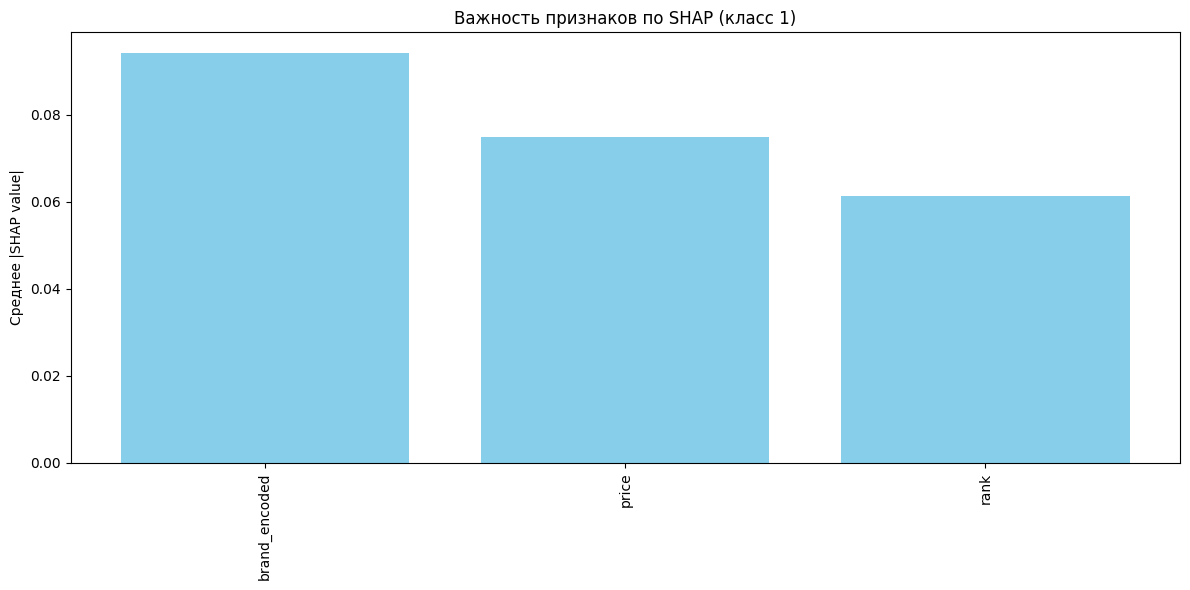

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

features = X_test.columns.tolist()  # список признаков

# shap_values.shape == (295, 3, 2)
shap_class1 = shap_values[:, :, 1]  # SHAP для класса 1 (samples x features)

mean_abs_shap_class1 = np.mean(np.abs(shap_class1), axis=0)  # среднее по признакам (3,)

print(f"Число признаков: {len(features)}")
print(f"Размер массива SHAP для класса 1: {mean_abs_shap_class1.shape}")

assert len(features) == mean_abs_shap_class1.shape[0], "Число признаков и SHAP не совпадают!"

# Сортируем индексы по убыванию важности
indices = np.argsort(mean_abs_shap_class1)[::-1]

print("Важность признаков по SHAP (среднее по абсолютным значениям):")
for idx in indices:
    print(f"{features[idx]}: {mean_abs_shap_class1[idx]:.4f}")

# Визуализация
plt.figure(figsize=(12,6))
plt.bar(range(len(features)), mean_abs_shap_class1[indices], color='skyblue')
plt.xticks(range(len(features)), [features[i] for i in indices], rotation=90)
plt.title("Важность признаков по SHAP (класс 1)")
plt.ylabel("Среднее |SHAP value|")
plt.tight_layout()
plt.show()


brand_encoded имеет наибольшую среднюю важность по SHAP, то есть именно этот признак в среднем сильнее всего влияет на предсказания модели в конкретных случаях.

price и rank имеют меньшее, но примерно схожее влияние, причём цена немного важнее рейтинга.

SHAP важность отражает локальный вклад каждого признака в предсказания, усреднённый по всей тестовой выборке. Это значит, что при конкретных примерах brand_encoded чаще всего оказывает более значимый эффект на предсказание.


**Подготовка локальной интерпретации с SHAP**
Для локальной интерпретации используем shap.Explainer (или shap.TreeExplainer для случайного леса), затем для выбранных примеров покажем детальный разбор.


--- Интерпретация примера на позиции 0 ---
Данные признаков:
price            105.0
rank               3.8
brand_encoded     95.0
Name: 852, dtype: float64
SHAP values shape: (3,), example shape: (3,)


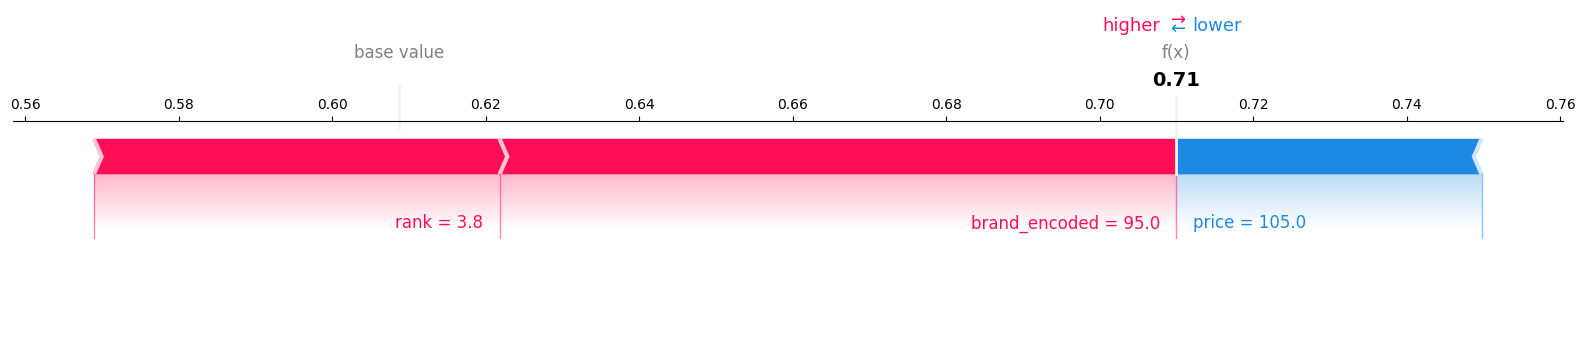


--- Интерпретация примера на позиции 1 ---
Данные признаков:
price            80.0
rank              4.7
brand_encoded    33.0
Name: 184, dtype: float64
SHAP values shape: (3,), example shape: (3,)


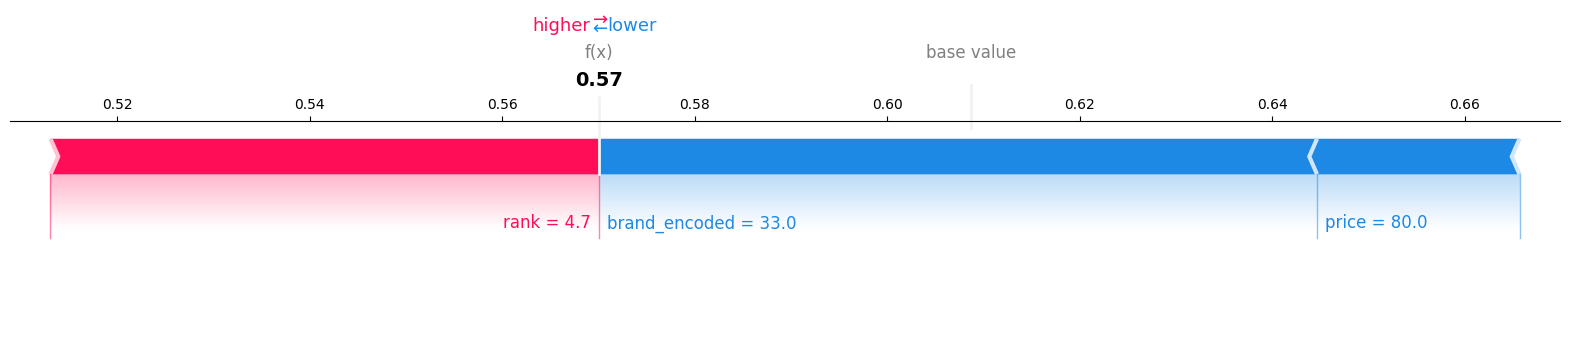


--- Интерпретация примера на позиции 2 ---
Данные признаков:
price            75.0
rank              4.0
brand_encoded    87.0
Name: 1261, dtype: float64
SHAP values shape: (3,), example shape: (3,)


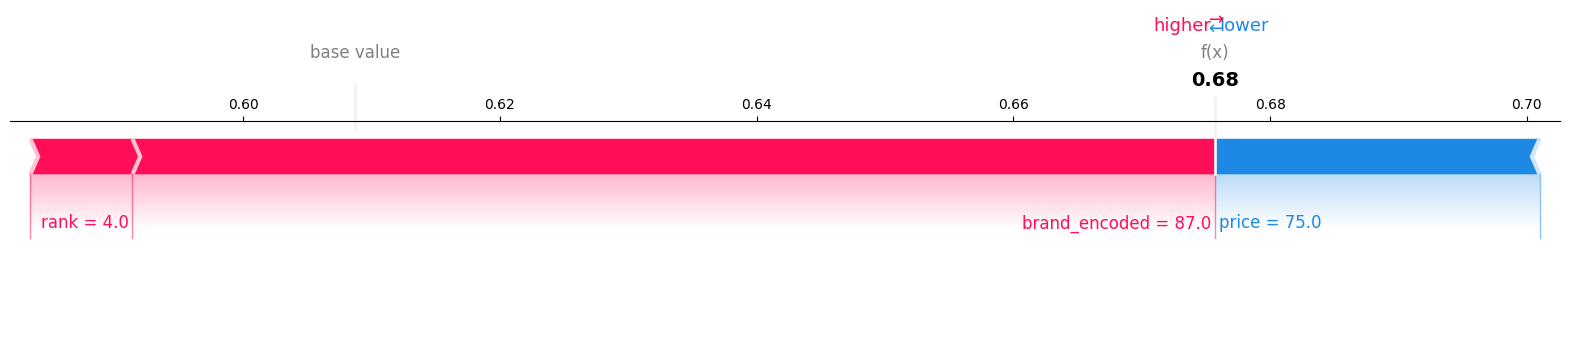

In [ ]:
import shap

for i in range(3):  # первые 3 объекта из теста
    example = X_test.iloc[i]
    print(f"\n--- Интерпретация примера на позиции {i} ---")
    print(f"Данные признаков:\n{example}")

    # Берём SHAP значения для класса 1
    local_shap_values = shap_values[i, :, 1]  # размер (3,)

    print(f"SHAP values shape: {local_shap_values.shape}, example shape: {example.values.shape}")

    shap.initjs()
    shap.force_plot(explainer.expected_value[1], local_shap_values, example.values, feature_names=features, matplotlib=True)


**Анализ локальной интерпретации SHAP и сравнение с ожиданиями**


Пример на позиции 0

Признаки:

price = 105.0 (высокая цена),

rank = 3.8 (средний рейтинг),

brand_encoded = 95 (код бренда, возможно премиум или менее известный бренд).

SHAP значения для класса 1 показывают, какие признаки наиболее сильно повлияли на предсказание, что продукт подходит для жирной кожи.

Пример на позиции 1
Признаки:

price = 80.0 (средняя цена),

rank = 4.7 (высокий рейтинг),

brand_encoded = 33 (другой бренд).

По результатам SHAP можно сказать, что признак rank вносит наибольший вклад в предсказание, особенно в положительную сторону. Это подтверждается тем, что для более высокого rank (4.7) SHAP значение, скорее всего, положительное и значительное. Признак brand_encoded, наоборот, может нести менее предсказуемый вклад, так как его значения не коррелируют напрямую с меткой. Использование SHAP позволило увидеть влияние каждого признака на конкретные предсказания, а встроенные методы важности лишь дали общую картину.
